# Using the stochastic Langevin wake environment

This notebook shows how to use `langevin_wake_env.py`, a cheap JAX surrogate of a turbulent square-back bluff-body wake (Ahmed-type), built for training RL agents.

**What the model contains**

| Mode | Equation (non-dimensional) | Source |
|---|---|---|
| Wake asymmetry $x$ (bistability) | $dx = \frac{1}{\tau_x}\big(x - x^3 + b + g_x u_{\text{diff}}\big)dt + \sqrt{2D/\tau_x}\,dW$ | Brackston et al. (2016) JFM 802, eq. 3.3, normalised as their eq. 3.6; after Rigas et al. (2015) JFM 778 R2 |
| Vortex shedding $A$ (complex) | $dA = \big[(\lambda - g_A u_{\text{sym}} + i\omega)A - \lambda\lvert A\rvert^2A\big]dt + \sigma_A\,dW_A$ | Stuart–Landau form of Brackston, Wynn & Morrison (2018) IJHFF 71, eq. 4 (simplified, see §8) |

**Contents**
1. Setup
2. The interface: spaces and actions
3. Running one episode
4. Checking the physics against theory
5. Domain randomisation
6. Batched rollouts with `vmap`
7. Baseline controllers
8. Plugging into a training loop, and modelling caveats

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

from langevin_wake_env import LangevinWake, WakeParams

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2a6fdb", "#e8743b", "#888888"
print("JAX", jax.__version__, "on", jax.devices())

JAX 0.12.1 on [CpuDevice(id=0)]


## 1. The interface

The environment follows the functional, gymnax-style convention: **no hidden state**. Every call takes a PRNG key and the current state, and returns a new state. That's what lets us `jit` and `vmap` it.

```python
obs, state = env.reset(key, params=None)               # params=None -> sample a random wake
obs, state, reward, done, info = env.step_env(key, state, action)   # no auto-reset
obs, state, reward, done, info = env.step(key, state, action)       # auto-resets when done
```

In [ ]:
env = LangevinWake(dt=0.01, substeps=5, max_steps=1000, hist=8, n_levels=3, randomise=True)

print("solver dt          :", env.dt)
print("control interval   :", env.dt * env.substeps)
print("episode length     :", env.max_steps, "control steps =", env.max_steps * env.dt * env.substeps, "time units")
print("number of actions  :", env.num_actions)
print("observation shape  :", env.observation_shape, "=", env.hist, "history x", env.obs_dim, "channels")
print("default parameters :")
for k, v in env.default_params()._asdict().items():
    print(f"   {k:10s} = {float(v):.3f}")

: 

### Action mapping

Actions are **discrete** (DiscoRL's policies are categorical). Each of the two jets takes one of `n_levels` values in $[0,1]$, and the action index is `i_L * n_levels + i_R`.
- Differential blowing $u_{\text{diff}} = j_R - j_L$ pushes the asymmetry $x$.
- Common blowing $u_{\text{sym}} = (j_L + j_R)/2$ (base bleed) damps the shedding.

In [3]:
print(f"{'action':>6} | {'jet L':>5} {'jet R':>5} | {'u_diff':>6} {'u_sym':>6}")
print("-" * 40)
for a in range(env.num_actions):
    jL, jR = float(env.levels[a // env.n_levels]), float(env.levels[a % env.n_levels])
    print(f"{a:>6} | {jL:5.2f} {jR:5.2f} | {jR - jL:+6.2f} {0.5 * (jL + jR):6.2f}")

action | jet L jet R | u_diff  u_sym
----------------------------------------
     0 |  0.00  0.00 |  +0.00   0.00
     1 |  0.00  0.50 |  +0.50   0.25
     2 |  0.00  1.00 |  +1.00   0.50
     3 |  0.50  0.00 |  -0.50   0.25
     4 |  0.50  0.50 |  +0.00   0.50
     5 |  0.50  1.00 |  +0.50   0.75
     6 |  1.00  0.00 |  -1.00   0.50
     7 |  1.00  0.50 |  -0.50   0.75
     8 |  1.00  1.00 |  +0.00   1.00


### Observation layout

The flat observation is the last `hist` frames stacked, oldest first. Each frame is
`[CoP_z, CoP_y, jet_L command, jet_R command]`, where
$CoP_z = x + \eta\,\mathrm{Re}(A) + \text{noise}$ and $CoP_y = \eta\,\mathrm{Im}(A) + \text{noise}$.

So `obs.reshape(hist, 4)[-1]` is the latest frame, and `obs[-4]` is the latest $CoP_z$.

## 2. Running one episode

A Python `for` loop works but is slow. The idiomatic JAX way is `jax.lax.scan`, which compiles the whole episode into one kernel. Below we run one episode with the jets off and keep the hidden state ($x$, $A$) to compare with what the agent actually sees.

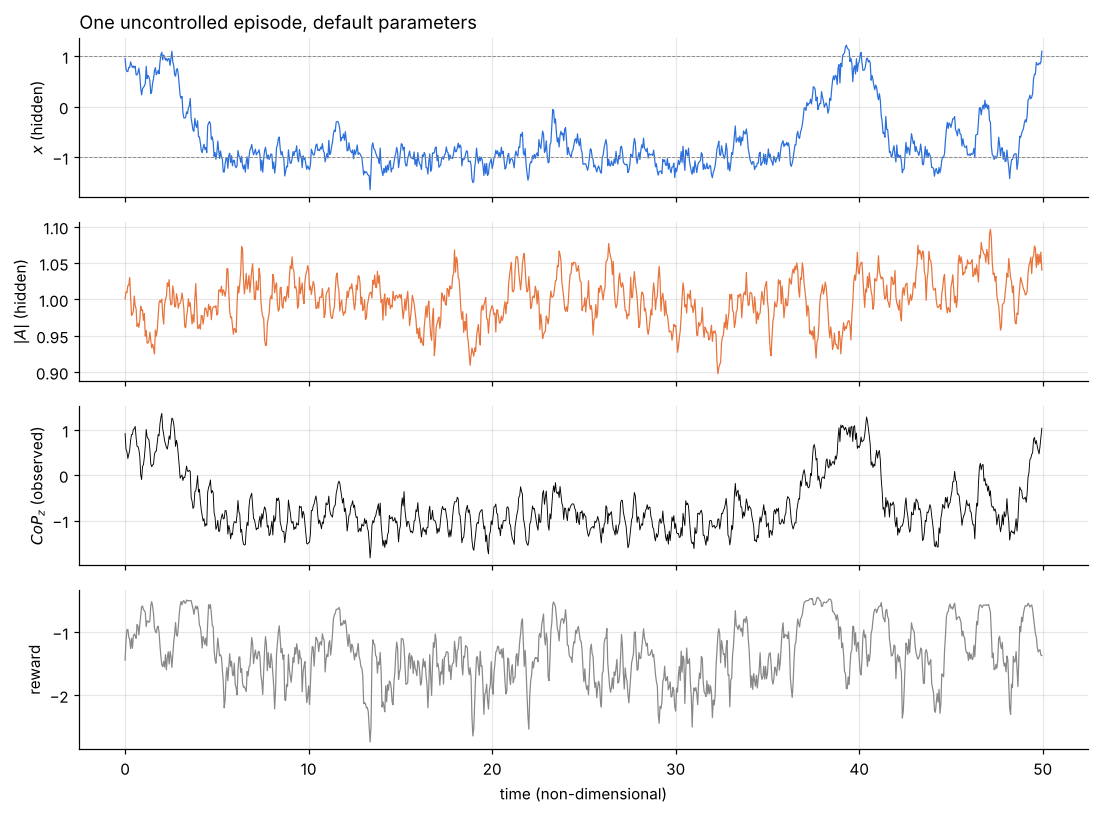

In [4]:
def rollout(env, key, policy, params=None, T=None):
    # Run one episode. policy(obs, key) -> action. Returns per-step arrays.
    T = T or env.max_steps
    k_reset, k_run = jax.random.split(key)
    obs, state = env.reset(k_reset, params)

    def body(carry, k):
        obs, state = carry
        k_pol, k_env = jax.random.split(k)
        action = policy(obs, k_pol)
        obs, state, r, done, info = env.step_env(k_env, state, action)
        out = dict(obs=obs.reshape(env.hist, env.obs_dim)[-1], x=state.x, A=state.A,
                   reward=r, cd=info["cd"], action=action)
        return (obs, state), out

    _, traj = jax.lax.scan(body, (obs, state), jax.random.split(k_run, T))
    return traj

zero_policy = lambda obs, key: jnp.int32(0)

params = env.default_params()
traj = jax.jit(lambda k: rollout(env, k, zero_policy, params))(jax.random.PRNGKey(1))
t = np.arange(env.max_steps) * env.dt * env.substeps

fig, ax = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
ax[0].plot(t, traj["x"], color=BLUE, lw=0.8); ax[0].set_ylabel("$x$ (hidden)")
ax[0].axhline(1, ls="--", c=GREY, lw=0.6); ax[0].axhline(-1, ls="--", c=GREY, lw=0.6)
ax[1].plot(t, np.abs(traj["A"]), color=ORANGE, lw=0.8); ax[1].set_ylabel("$|A|$ (hidden)")
ax[2].plot(t, traj["obs"][:, 0], color="k", lw=0.6); ax[2].set_ylabel("$CoP_z$ (observed)")
ax[3].plot(t, traj["reward"], color=GREY, lw=0.8); ax[3].set_ylabel("reward")
ax[3].set_xlabel("time (non-dimensional)")
ax[0].set_title("One uncontrolled episode, default parameters", loc="left")
fig.tight_layout()

The asymmetry sits in one well and occasionally flips. The shedding amplitude hovers around $|A| = 1$. The observed $CoP_z$ is the asymmetry with shedding and sensor noise on top, which is what the agent has to work with.

## 3. Checking the physics against theory

Before training on a surrogate, check that it does what the equations say. Three checks:

1. **Stationary distribution of $x$.** For $dx = -\frac{1}{\tau_x}V'(x)\,dt + \sqrt{2D/\tau_x}\,dW$, the Fokker–Planck equation gives $P(x) \propto \exp[-V(x)/D]$ with $V(x) = -\tfrac{1}{2}x^2 + \tfrac{1}{4}x^4 - b\,x$. This is the normalised form of Brackston et al. (2016) eq. 3.5.
2. **Switching time.** Kramers' law gives the mean time spent in a well:
$$T_K = \frac{2\pi\,\tau_x}{\sqrt{V''(\pm1)\,|V''(0)|}}\;e^{\Delta V/D} = \sqrt{2}\,\pi\,\tau_x\,e^{1/(4D)}$$
It's only accurate when the barrier is large compared with the noise ($\Delta V/D \gg 1$), so expect rough agreement.
3. **Shedding spectrum.** $\mathrm{Re}(A)$ should peak near $f = \omega/2\pi$, broadened by the phase random walk.

We run 128 long uncontrolled trajectories with the default parameters.

In [5]:
long_env = LangevinWake(max_steps=10**9, randomise=False)   # never hits 'done'
p = long_env.default_params()
N_TRAJ, T_LONG = 128, 20_000                                 # 20k control steps = 1000 time units each

run = jax.jit(jax.vmap(lambda k: rollout(long_env, k, zero_policy, p, T=T_LONG)))
t0 = time.time()
long = run(jax.random.split(jax.random.PRNGKey(2), N_TRAJ))
jax.block_until_ready(long)
print(f"{N_TRAJ * T_LONG * long_env.substeps / 1e6:.0f}M solver steps in {time.time() - t0:.1f} s (incl. compile)")
X = np.asarray(long["x"])            # (N_TRAJ, T_LONG)
A = np.asarray(long["A"])

13M solver steps in 4.0 s (incl. compile)


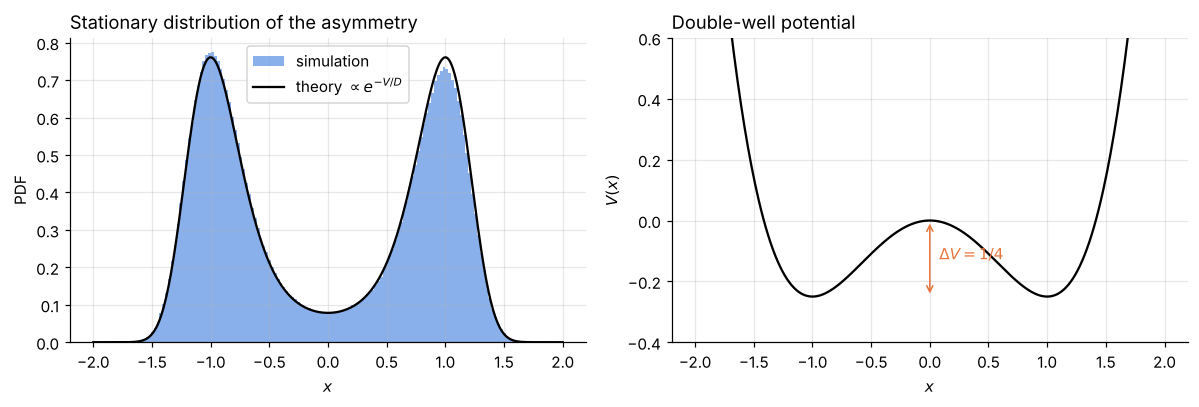

In [6]:
D, tau, b = float(p.D), float(p.tau_x), float(p.bias)
xs = np.linspace(-2, 2, 400)
V = -0.5 * xs**2 + 0.25 * xs**4 - b * xs
P = np.exp(-V / D); P /= np.trapezoid(P, xs)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(X[:, 500:].ravel(), bins=150, density=True, color=BLUE, alpha=0.55, label="simulation")
ax[0].plot(xs, P, color="k", lw=1.5, label=r"theory $\propto e^{-V/D}$")
ax[0].set_xlabel("$x$"); ax[0].set_ylabel("PDF"); ax[0].legend()
ax[0].set_title("Stationary distribution of the asymmetry", loc="left")

ax[1].plot(xs, V, color="k")
ax[1].set_xlabel("$x$"); ax[1].set_ylabel("$V(x)$"); ax[1].set_ylim(-0.4, 0.6)
ax[1].annotate("", xy=(0, 0), xytext=(0, -0.25), arrowprops=dict(arrowstyle="<->", color=ORANGE))
ax[1].text(0.08, -0.13, r"$\Delta V = 1/4$", color=ORANGE)
ax[1].set_title("Double-well potential", loc="left")
fig.tight_layout()

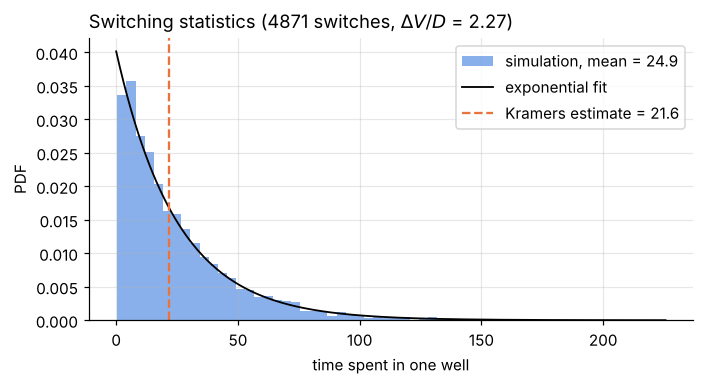

In [7]:
def residence_times(X, dt_ctrl, thresh=0.7):
    # Durations spent in a well, with hysteresis: a switch needs x to cross the opposite threshold.
    out = []
    for xi in X:
        side, t_last = np.sign(xi[0]), None
        for i, v in enumerate(xi):
            if (side > 0 and v < -thresh) or (side < 0 and v > thresh):
                if t_last is not None:
                    out.append((i - t_last) * dt_ctrl)
                side, t_last = -side, i
    return np.array(out)

dt_ctrl = long_env.dt * long_env.substeps
rt = residence_times(X, dt_ctrl)
T_K = np.sqrt(2) * np.pi * tau * np.exp(1 / (4 * D))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(rt, bins=60, density=True, color=BLUE, alpha=0.55, label=f"simulation, mean = {rt.mean():.1f}")
tt = np.linspace(0, rt.max(), 300)
ax.plot(tt, np.exp(-tt / rt.mean()) / rt.mean(), "k", lw=1.2, label="exponential fit")
ax.axvline(T_K, color=ORANGE, ls="--", label=f"Kramers estimate = {T_K:.1f}")
ax.set_xlabel("time spent in one well"); ax.set_ylabel("PDF"); ax.legend()
ax.set_title(f"Switching statistics ({len(rt)} switches, $\\Delta V/D$ = {0.25 / D:.2f})", loc="left")
fig.tight_layout()

The residence times are close to exponential, which is the signature of noise-driven escape over a barrier, and the mean is in the same range as the Kramers estimate. The gap is expected at this barrier-to-noise ratio. Kramers' law becomes exact only as $\Delta V/D \to \infty$, and the hysteresis thresholds also shift the count slightly.

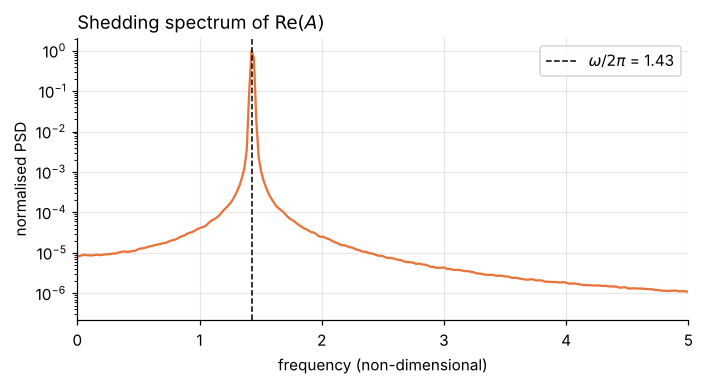

In [8]:
from numpy.fft import rfft, rfftfreq

sig = A.real[:, 500:]
sig = sig - sig.mean(axis=1, keepdims=True)
nseg = 1024
segs = sig[:, : (sig.shape[1] // nseg) * nseg].reshape(-1, nseg) * np.hanning(nseg)
psd = (np.abs(rfft(segs, axis=1)) ** 2).mean(axis=0)
f = rfftfreq(nseg, d=dt_ctrl)
f0 = float(p.omega) / (2 * np.pi)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.semilogy(f, psd / psd.max(), color=ORANGE)
ax.axvline(f0, color="k", ls="--", lw=1, label=rf"$\omega/2\pi$ = {f0:.2f}")
ax.set_xlim(0, 5); ax.set_xlabel("frequency (non-dimensional)"); ax.set_ylabel("normalised PSD")
ax.set_title(r"Shedding spectrum of $\mathrm{Re}(A)$", loc="left"); ax.legend()
fig.tight_layout()

The peak sits at $\omega/2\pi$ and has finite width. That width comes from the phase random walk, which is why turbulent shedding looks quasi-periodic rather than like a clean sine wave.

## 4. Domain randomisation

With `randomise=True`, each `reset` draws a new wake from a family of parameters (`LangevinWake.sample_params`). The parameters live in the state, so every environment in a batch can be a different "body". This distribution is what you'd meta-train on.

Kramers switching time across the family: median 23.8, 5-95% range 9.3 to 62.6  (episode = 50 time units)


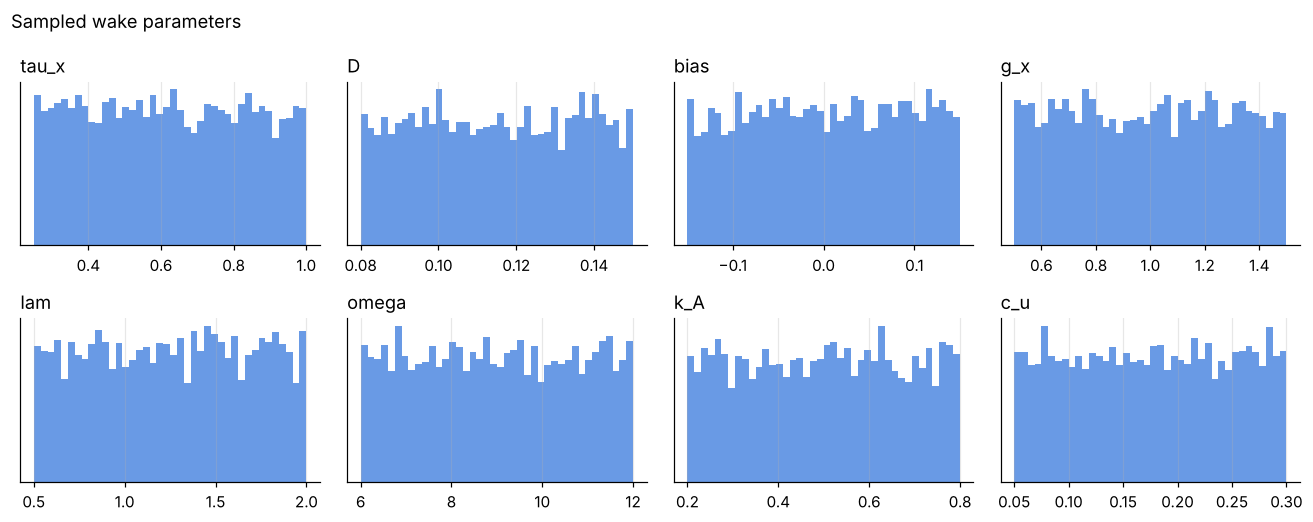

In [9]:
keys = jax.random.split(jax.random.PRNGKey(3), 4000)
samples = jax.vmap(env.sample_params)(keys)

show = ["tau_x", "D", "bias", "g_x", "lam", "omega", "k_A", "c_u"]
fig, axs = plt.subplots(2, 4, figsize=(12, 4.8))
for a, name in zip(axs.ravel(), show):
    a.hist(np.asarray(getattr(samples, name)), bins=40, color=BLUE, alpha=0.7)
    a.set_title(name, loc="left"); a.set_yticks([])
fig.suptitle("Sampled wake parameters", x=0.01, ha="left")
fig.tight_layout()

D_s, tau_s = np.asarray(samples.D), np.asarray(samples.tau_x)
T_s = np.sqrt(2) * np.pi * tau_s * np.exp(1 / (4 * D_s))
print(f"Kramers switching time across the family: median {np.median(T_s):.1f}, "
      f"5-95% range {np.percentile(T_s, 5):.1f} to {np.percentile(T_s, 95):.1f}  (episode = 50 time units)")

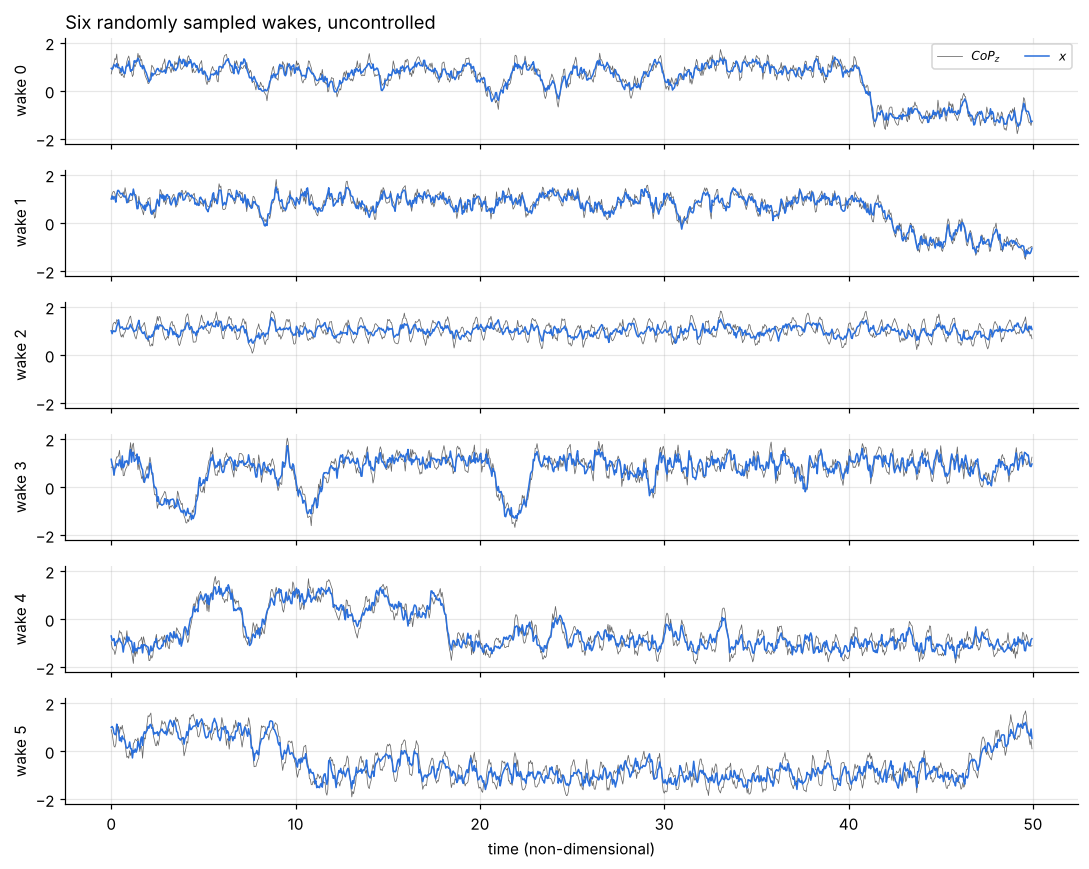

In [10]:
sample_run = jax.jit(jax.vmap(lambda k: rollout(env, k, zero_policy)))   # params=None -> random wake
many = sample_run(jax.random.split(jax.random.PRNGKey(4), 6))

fig, axs = plt.subplots(6, 1, figsize=(10, 8), sharex=True)
for i, a in enumerate(axs):
    a.plot(t, many["obs"][i, :, 0], color="k", lw=0.5, alpha=0.6, label="$CoP_z$")
    a.plot(t, many["x"][i], color=BLUE, lw=1.0, label="$x$")
    a.set_ylim(-2.2, 2.2); a.set_ylabel(f"wake {i}")
axs[0].legend(loc="upper right", ncol=2, fontsize=8)
axs[-1].set_xlabel("time (non-dimensional)")
axs[0].set_title("Six randomly sampled wakes, uncontrolled", loc="left")
fig.tight_layout()

Some wakes switch often, some hardly at all, some are biased towards one side, and the sensor noise and shedding visibility vary. The asymmetry is easy to read off $CoP_z$ in some wakes and buried in others.

## 5. Batched rollouts with `vmap`

`jax.vmap` turns the single-environment `rollout` into a batched one, and `jax.jit` compiles it. The first call includes compilation, so we time the second.

In [11]:
for N in [64, 512, 4096]:
    f = jax.jit(jax.vmap(lambda k: rollout(env, k, zero_policy)))
    ks = jax.random.split(jax.random.PRNGKey(5), N)
    jax.block_until_ready(f(ks))                       # compile
    t0 = time.time(); jax.block_until_ready(f(ks)); el = time.time() - t0
    print(f"N = {N:5d} envs x {env.max_steps} steps: {el:6.2f} s   "
          f"-> {N * env.max_steps / el / 1e6:5.2f}M control steps/s, "
          f"{N * env.max_steps * env.substeps / el / 1e6:5.1f}M solver steps/s")

N =    64 envs x 1000 steps:   0.02 s   ->  3.74M control steps/s,  18.7M solver steps/s


N =   512 envs x 1000 steps:   0.17 s   ->  3.09M control steps/s,  15.5M solver steps/s


N =  4096 envs x 1000 steps:   1.89 s   ->  2.17M control steps/s,  10.8M solver steps/s


These numbers are for whatever device this runs on. On a GPU, throughput keeps rising with batch size well past what a CPU can handle.

## 6. Baseline controllers

Simple baselines tell you how much a learned controller should be able to improve. Here are four policies, each a pure function of the observation:

- **zero**: jets off
- **random**: uniform random action
- **bang-bang**: fire the jet that pushes the wake back towards the centre, based on the latest $CoP_z$
- **bang-bang + bleed**: the same, but both jets at least at half power (base bleed)

In [12]:
n = env.n_levels

def bang_bang(obs, key, deadband=0.1):
    copz = obs[-4]                                     # latest CoP_z
    iL = jnp.where(copz > deadband, n - 1, 0)          # wake leaning +: blow left jet
    iR = jnp.where(copz < -deadband, n - 1, 0)         # wake leaning -: blow right jet
    return (iL * n + iR).astype(jnp.int32)

def bang_bang_bleed(obs, key):
    a = bang_bang(obs, key)
    iL, iR = jnp.maximum(a // n, 1), jnp.maximum(a % n, 1)
    return (iL * n + iR).astype(jnp.int32)

policies = {
    "zero": zero_policy,
    "random": lambda obs, key: jax.random.randint(key, (), 0, env.num_actions),
    "bang-bang": bang_bang,
    "bang-bang + bleed": bang_bang_bleed,
}

N_EVAL = 1024
eval_keys = jax.random.split(jax.random.PRNGKey(6), N_EVAL)   # same wakes for every policy
results = {}
for name, pol in policies.items():
    tr = jax.jit(jax.vmap(lambda k: rollout(env, k, pol)))(eval_keys)
    results[name] = {k: np.asarray(v) for k, v in tr.items()}
    r = results[name]
    print(f"{name:18s} mean reward {r['reward'].mean():+.3f}   mean drag proxy {r['cd'].mean():.3f}   "
          f"mean |x| {np.abs(r['x']).mean():.2f}   mean |A| {np.abs(r['A']).mean():.2f}")

zero               mean reward -1.390   mean drag proxy 2.390   mean |x| 0.90   mean |A| 1.00


random             mean reward -1.224   mean drag proxy 2.114   mean |x| 0.88   mean |A| 0.68


bang-bang          mean reward -0.589   mean drag proxy 1.466   mean |x| 0.34   mean |A| 0.74


bang-bang + bleed  mean reward -0.691   mean drag proxy 1.488   mean |x| 0.50   mean |A| 0.48


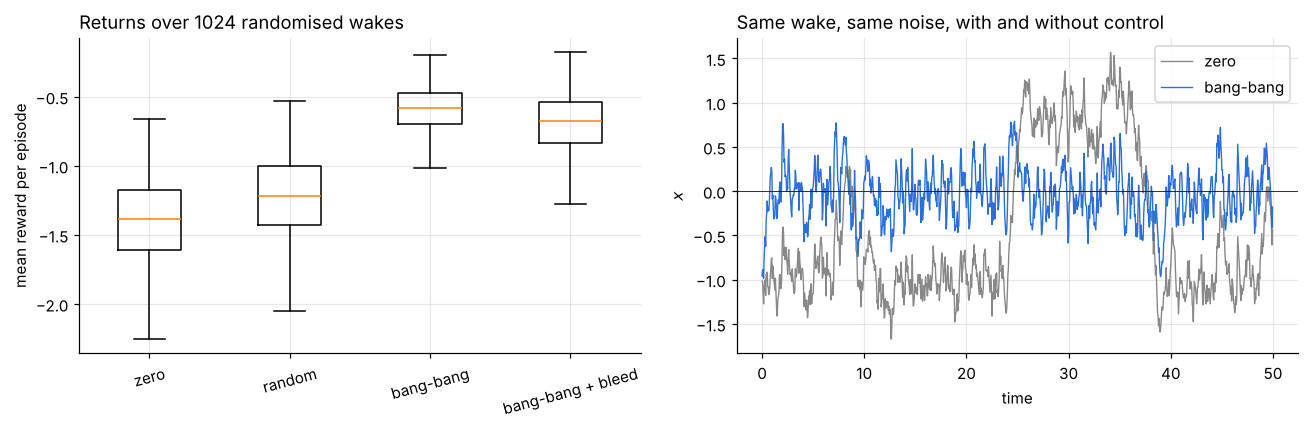

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
names = list(results)
ep_ret = [results[k]["reward"].mean(axis=1) for k in names]
ax[0].boxplot(ep_ret, showfliers=False)
ax[0].set_xticks(range(1, len(names) + 1), names, rotation=15)
ax[0].set_ylabel("mean reward per episode")
ax[0].set_title(f"Returns over {N_EVAL} randomised wakes", loc="left")

i = 0
for name, c in [("zero", GREY), ("bang-bang", BLUE)]:
    ax[1].plot(t, results[name]["x"][i], color=c, lw=0.9, label=name)
ax[1].axhline(0, color="k", lw=0.5)
ax[1].set_xlabel("time"); ax[1].set_ylabel("$x$"); ax[1].legend()
ax[1].set_title("Same wake, same noise, with and without control", loc="left")
fig.tight_layout()

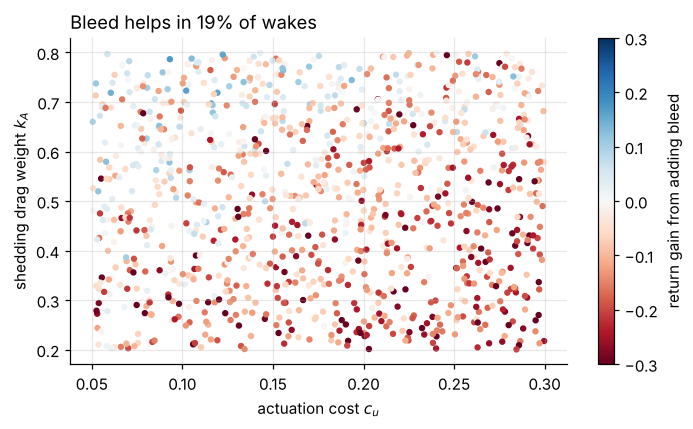

In [14]:
# Does base bleed pay off? It depends on the wake: compare per-wake returns.
gain = results["bang-bang + bleed"]["reward"].mean(1) - results["bang-bang"]["reward"].mean(1)
# rollout() resets with the first half of its key, so recover the same per-wake params
wake_params = jax.vmap(lambda k: env.reset(jax.random.split(k)[0])[1].params)(eval_keys)
c_u, k_A = np.asarray(wake_params.c_u), np.asarray(wake_params.k_A)

fig, ax = plt.subplots(figsize=(6.5, 4))
sc = ax.scatter(c_u, k_A, c=gain, cmap="RdBu", vmin=-0.3, vmax=0.3, s=10)
plt.colorbar(sc, label="return gain from adding bleed")
ax.set_xlabel("actuation cost $c_u$"); ax.set_ylabel("shedding drag weight $k_A$")
ax.set_title(f"Bleed helps in {np.mean(gain > 0) * 100:.0f}% of wakes", loc="left")
fig.tight_layout()

The right strategy depends on the wake. Base bleed pays when shedding matters a lot for drag ($k_A$ high) and blowing is cheap ($c_u$ low). A good general rule has to infer which kind of wake it's in from the observations alone, which is the point of randomising.

## 7. Plugging into a training loop

RL libraries want a batched step that resets finished environments automatically. That's `env.step`. Below is the minimal rollout-collection pattern most JAX RL code uses (PureJaxRL style). The `policy_apply` here is a stand-in; swap in your agent's network.

In [15]:
N_ENVS, N_STEPS = 256, 128

v_reset = jax.vmap(env.reset, in_axes=(0, None))
v_step = jax.vmap(env.step, in_axes=(0, 0, 0))

def policy_apply(policy_params, obs, key):
    # Stand-in for a network forward pass: returns actions and log-probs.
    logits = jnp.zeros((obs.shape[0], env.num_actions))
    actions = jax.random.categorical(key, logits)
    logp = jax.nn.log_softmax(logits)[jnp.arange(obs.shape[0]), actions]
    return actions, logp

@jax.jit
def collect(runner_state, policy_params):
    def body(carry, _):
        obs, states, key = carry
        key, k_pol, k_env = jax.random.split(key, 3)
        actions, logp = policy_apply(policy_params, obs, k_pol)
        obs2, states, rewards, dones, info = v_step(jax.random.split(k_env, N_ENVS), states, actions)
        transition = dict(obs=obs, action=actions, logp=logp, reward=rewards, done=dones)
        return (obs2, states, key), transition
    runner_state, batch = jax.lax.scan(body, runner_state, None, length=N_STEPS)
    return runner_state, batch

key = jax.random.PRNGKey(7)
key, k0 = jax.random.split(key)
obs, states = v_reset(jax.random.split(k0, N_ENVS), None)
runner_state = (obs, states, key)

runner_state, batch = collect(runner_state, None)
print({k: v.shape for k, v in batch.items()})
# -> feed `batch` (time, env, ...) into your loss; call `collect` again with the carried runner_state

{'action': (128, 256), 'done': (128, 256), 'logp': (128, 256), 'obs': (128, 256, 32), 'reward': (128, 256)}


**Connecting to DiscoRL.** The DiscoRL code has its own environment wrappers. Check how it expects batches (time-major vs batch-major), whether it handles resets itself, and how it marks episode ends (here `done` means time-limit truncation, not termination). A thin adapter around `env.reset` / `env.step` should be all you need.

## 8. Modelling caveats

Know what the surrogate assumes before you draw conclusions from it:

- **Asymmetry mode:** the normalised 1D Langevin model of Brackston et al. (2016), with wells at $x = \pm1$ and time in units of $\tau_x = 1/\alpha$. The parameter *ranges* are design choices, not fitted to data. Calibrate them against time-resolved base pressure (your REACT logs or published data).
- **Shedding mode:** a simplified version of Brackston, Wynn & Morrison (2018) eq. 4:
  - the frequency doesn't shift with amplitude ($\lambda_i = 0$);
  - the noise is independent in the real and imaginary parts (the paper uses $\sigma(1+i)\xi$, i.e. correlated);
  - the actuation acts by **lowering the growth rate** (base bleed). In the paper, the flaps enter as an **additive** forcing $u(\theta)$. The base-bleed mechanism is my modelling assumption.
- **Drag proxy:** $c_d = 1 + k_x x^2 + k_A|A|^2$ is an assumption. Brackston et al. (2018) found that feedback suppression of shedding did not measurably reduce drag on the real body, so $k_A$ may deserve a smaller range than used here.
- **No coupling** between the two modes, and no sensor or advective delay beyond the actuator lag. Both are easy to add in `_substep`.

**References**
- Rigas, Morgans, Brackston & Morrison (2015). *Diffusive dynamics and stochastic models of turbulent axisymmetric wakes.* J. Fluid Mech. 778, R2.
- Brackston, García de la Cruz, Wynn, Rigas & Morrison (2016). *Stochastic modelling and feedback control of bistability in a turbulent bluff body wake.* J. Fluid Mech. 802.
- Brackston, Wynn & Morrison (2018). *Modelling and feedback control of vortex shedding for drag reduction of a turbulent bluff body wake.* Int. J. Heat Fluid Flow 71, 127–136.